# Online Store Sales Data Analysis
**Portfolio Project | Python · Pandas · Matplotlib · Jupyter Notebook**

## Project Overview
This project analyzes fictional online-store transactions to understand sales performance, profitability, product categories, and customer purchasing patterns.

**Objectives**
- Load and inspect sales data
- Clean missing and duplicate records
- Create useful business metrics
- Explore sales and profit trends
- Visualize key findings
- Present actionable business recommendations

> **Dataset note:** This is a fictional practice dataset created for portfolio and learning purposes. It does not represent a real company.

## 1. Import Libraries

We use:
- `pandas` for data handling
- `numpy` for numerical operations
- `matplotlib` for charts

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Create / Load the Dataset

The code below creates a reproducible fictional dataset so the notebook can run without downloading an external file. For a real-world project, replace this section with `pd.read_csv("your_file.csv")`.

In [ ]:
# Create a fictional online-store dataset
rng = np.random.default_rng(42)
n = 500

products = {
    "Electronics": ["Headphones", "Keyboard", "Mouse", "Speaker"],
    "Home": ["Lamp", "Water Bottle", "Storage Box", "Cushion"],
    "Stationery": ["Notebook", "Pen Set", "Planner", "Desk Organizer"]
}
categories = rng.choice(list(products.keys()), size=n, p=[0.40, 0.35, 0.25])
product_names = [rng.choice(products[cat]) for cat in categories]

unit_prices = []
for cat, product in zip(categories, product_names):
    if cat == "Electronics":
        unit_prices.append(rng.integers(20, 151))
    elif cat == "Home":
        unit_prices.append(rng.integers(8, 81))
    else:
        unit_prices.append(rng.integers(3, 36))

dates = pd.to_datetime(rng.choice(pd.date_range("2025-01-01", "2025-12-31"), size=n))
quantity = rng.integers(1, 6, size=n)
discount = rng.choice([0, 0.05, 0.10, 0.15], size=n, p=[0.45, 0.25, 0.20, 0.10])
cost_rate = rng.uniform(0.45, 0.75, size=n)

df = pd.DataFrame({
    "Order_ID": [f"ORD-{i:04d}" for i in range(1, n + 1)],
    "Order_Date": dates,
    "Category": categories,
    "Product": product_names,
    "Quantity": quantity,
    "Unit_Price": unit_prices,
    "Discount": discount,
    "Cost_Rate": cost_rate
})

# Add a few realistic data-quality issues for cleaning practice
df.loc[7, "Product"] = np.nan
df.loc[18, "Category"] = " home "
df = pd.concat([df, df.iloc[[2]]], ignore_index=True)

df.head()

,Order_ID,Order_Date,Category,Product,Quantity,Unit_Price,Discount,Cost_Rate
0,ORD-0001,2025-11-17,Stationery,Desk Organizer,4,20,0.05,0.70
1,ORD-0002,2025-01-23,Home,Storage Box,1,27,0.15,0.58
2,ORD-0003,2025-05-26,Stationery,Planner,4,10,0.00,0.74
3,ORD-0004,2025-06-17,Home,Cushion,1,31,0.00,0.65
4,ORD-0005,2025-10-19,Electronics,Headphones,1,98,0.10,0.48


## 3. Understand the Data

Before analysis, inspect the dataset's size, columns, data types, and summary statistics.

In [ ]:
print("Dataset shape:", df.shape)
print("\\nColumn information:")
df.info()

print("\\nSummary statistics:")
display(df.describe(include="all"))

Dataset shape: (501, 8)
\nColumn information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order_ID    501 non-null    object        
 1   Order_Date  501 non-null    datetime64[ns]
 2   Category    501 non-null    object        
 3   Product     500 non-null    object        
 4   Quantity    501 non-null    int64         
 5   Unit_Price  501 non-null    int64         
 6   Discount    501 non-null    float64       
 7   Cost_Rate   501 non-null    float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(3)
memory usage: 31.4+ KB
\nSummary statistics:


,Order_ID,Order_Date,Category,Product,Quantity,Unit_Price,Discount,Cost_Rate
count,501,501,501,500,501.00,501.00,501.00,501.00
unique,500,NaN,4,12,NaN,NaN,NaN,NaN
top,ORD-0003,NaN,Electronics,Keyboard,NaN,NaN,NaN,NaN
freq,2,NaN,196,60,NaN,NaN,NaN,NaN
mean,NaN,2025-06-28 20:10:03.592814336,NaN,NaN,3.05,52.57,0.05,0.60
min,NaN,2025-01-01 00:00:00,NaN,NaN,1.00,3.00,0.00,0.45
25%,NaN,2025-04-05 00:00:00,NaN,NaN,2.00,22.00,0.00,0.52
50%,NaN,2025-06-19 00:00:00,NaN,NaN,3.00,43.00,0.05,0.59
75%,NaN,2025-09-27 00:00:00,NaN,NaN,4.00,73.00,0.10,0.67
max,NaN,2025-12-31 00:00:00,NaN,NaN,5.00,150.00,0.15,0.75


## 4. Data Cleaning

We check for duplicate rows, missing values, and inconsistent category formatting. Missing product names are labelled as `Unknown Product` for this practice exercise.

In [ ]:
# Check data quality
print("Duplicate rows:", df.duplicated().sum())
print("\\nMissing values:")
display(df.isna().sum())

# Remove duplicate records
df = df.drop_duplicates().copy()

# Standardize text fields
df["Category"] = df["Category"].str.strip().str.title()
df["Product"] = df["Product"].fillna("Unknown Product").str.strip()

# Ensure correct data types
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

print("Shape after cleaning:", df.shape)
print("Remaining missing values:", df.isna().sum().sum())

Duplicate rows: 1
\nMissing values:


,0
Order_ID,0
Order_Date,0
Category,0
Product,1
Quantity,0
Unit_Price,0
Discount,0
Cost_Rate,0


Shape after cleaning: (500, 8)
Remaining missing values: 0


## 5. Create Business Metrics

We calculate gross sales, discount amount, net sales, estimated cost, and profit. These are simplified assumptions for a learning dataset.

In [ ]:
df["Gross_Sales"] = df["Quantity"] * df["Unit_Price"]
df["Discount_Amount"] = df["Gross_Sales"] * df["Discount"]
df["Net_Sales"] = df["Gross_Sales"] - df["Discount_Amount"]
df["Estimated_Cost"] = df["Net_Sales"] * df["Cost_Rate"]
df["Profit"] = df["Net_Sales"] - df["Estimated_Cost"]
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

display(df.head())

,Order_ID,Order_Date,Category,Product,Quantity,Unit_Price,Discount,Cost_Rate,Gross_Sales,Discount_Amount,Net_Sales,Estimated_Cost,Profit,Month
0,ORD-0001,2025-11-17,Stationery,Desk Organizer,4,20,0.05,0.70,80,4.00,76.00,53.41,22.59,2025-11
1,ORD-0002,2025-01-23,Home,Storage Box,1,27,0.15,0.58,27,4.05,22.95,13.40,9.55,2025-01
2,ORD-0003,2025-05-26,Stationery,Planner,4,10,0.00,0.74,40,0.00,40.00,29.44,10.56,2025-05
3,ORD-0004,2025-06-17,Home,Cushion,1,31,0.00,0.65,31,0.00,31.00,20.00,11.00,2025-06
4,ORD-0005,2025-10-19,Electronics,Headphones,1,98,0.10,0.48,98,9.80,88.20,42.76,45.44,2025-10


## 6. Key Performance Indicators (KPIs)

These summary metrics provide a quick overview of store performance.

In [ ]:
total_orders = df["Order_ID"].nunique()
total_units = df["Quantity"].sum()
total_sales = df["Net_Sales"].sum()
total_profit = df["Profit"].sum()
average_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100

kpi_summary = pd.DataFrame({
    "Metric": ["Total Orders", "Units Sold", "Net Sales", "Estimated Profit",
               "Average Order Value", "Profit Margin"],
    "Value": [total_orders, total_units, total_sales, total_profit,
              average_order_value, profit_margin]
})
display(kpi_summary)

,Metric,Value
0,Total Orders,500.00
1,Units Sold,"1,524.00"
2,Net Sales,"75,832.30"
3,Estimated Profit,"30,661.63"
4,Average Order Value,151.66
5,Profit Margin,40.43


## 7. Sales by Category

This analysis compares net sales across product categories.

,Net_Sales
Category,
Electronics,"45,405.80"
Home,"24,106.60"
Stationery,"6,319.90"


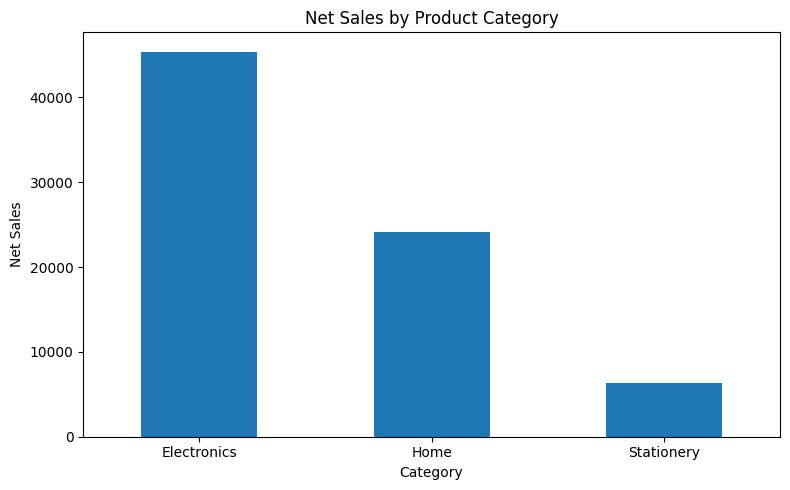

In [ ]:
category_sales = df.groupby("Category")["Net_Sales"].sum().sort_values(ascending=False)
display(category_sales)

plt.figure(figsize=(8, 5))
category_sales.plot(kind="bar")
plt.title("Net Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Net Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Monthly Sales Trend

Grouping sales by month helps identify stronger and weaker periods.

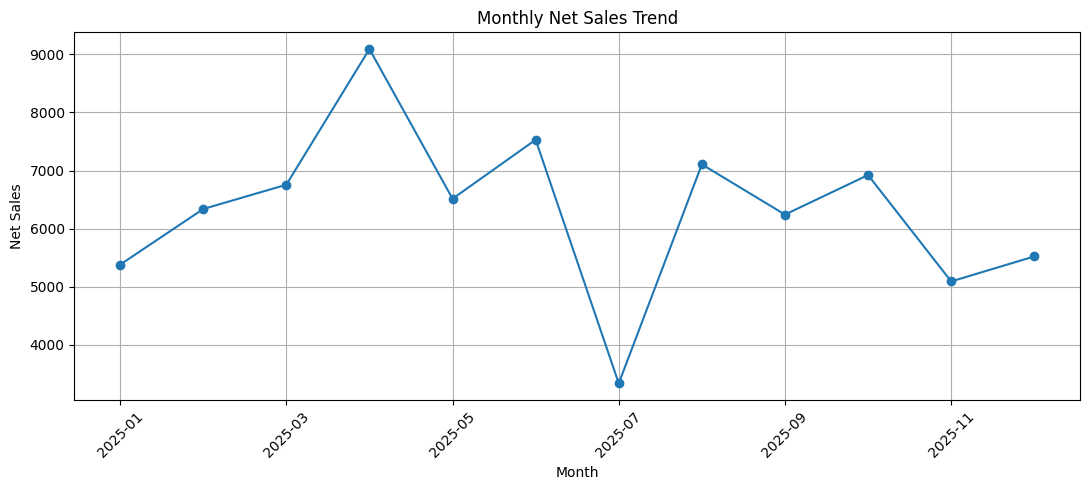

In [ ]:
monthly_sales = df.groupby("Month")["Net_Sales"].sum()

plt.figure(figsize=(11, 5))
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Net Sales Trend")
plt.xlabel("Month")
plt.ylabel("Net Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## 9. Profit by Category

Sales alone do not tell the whole story. Profit comparison helps show which categories contribute more estimated profit.

,Profit
Category,
Electronics,"18,352.81"
Home,"9,788.87"
Stationery,"2,519.95"


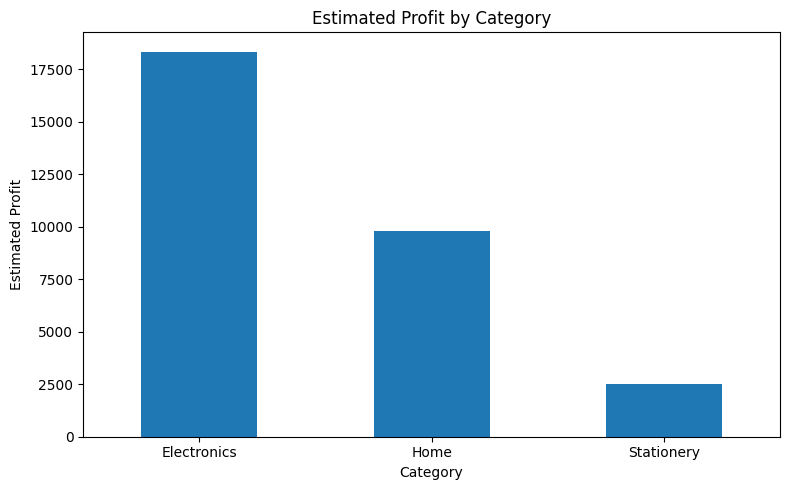

In [ ]:
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)
display(category_profit)

plt.figure(figsize=(8, 5))
category_profit.plot(kind="bar")
plt.title("Estimated Profit by Category")
plt.xlabel("Category")
plt.ylabel("Estimated Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Top 5 Products by Net Sales

This identifies the products generating the highest net sales in the fictional dataset.

,Net_Sales
Product,
Mouse,"14,864.00"
Keyboard,"12,758.00"
Speaker,"10,048.65"
Headphones,"7,735.15"
Cushion,"6,644.40"


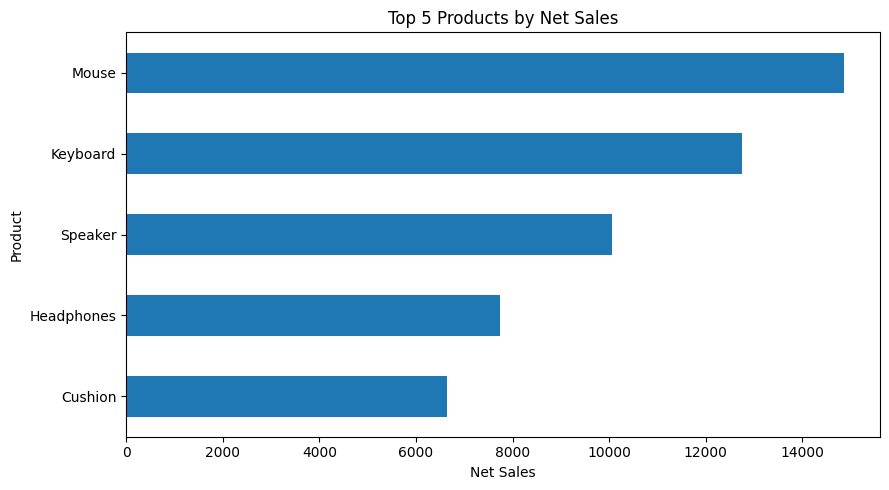

In [ ]:
top_products = (
    df.groupby("Product")["Net_Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
)
display(top_products)

plt.figure(figsize=(9, 5))
top_products.sort_values().plot(kind="barh")
plt.title("Top 5 Products by Net Sales")
plt.xlabel("Net Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

## 11. Business Findings

The following code generates findings from the dataset, rather than relying on guessed values.

In [ ]:
best_sales_category = category_sales.idxmax()
best_profit_category = category_profit.idxmax()
best_month = monthly_sales.idxmax()
best_product = top_products.idxmax()

print("BUSINESS FINDINGS")
print("-----------------")
print(f"1. {best_sales_category} is the highest sales-generating category.")
print(f"2. {best_profit_category} contributes the highest estimated profit.")
print(f"3. {best_month} is the strongest month by net sales.")
print(f"4. {best_product} is the top product by net sales.")
print(f"5. Overall estimated profit margin is {profit_margin:.1f}%.")

BUSINESS FINDINGS
-----------------
1. Electronics is the highest sales-generating category.
2. Electronics contributes the highest estimated profit.
3. 2025-04 is the strongest month by net sales.
4. Mouse is the top product by net sales.
5. Overall estimated profit margin is 40.4%.


## 12. Recommendations

Based on the results above, a store manager could:

1. Review the best-performing category and ensure popular products remain available.
2. Investigate categories with lower profit to understand pricing and cost issues.
3. Study the strongest sales month to identify seasonal demand patterns.
4. Use product-level results to guide promotions and inventory decisions.
5. Monitor profit margin alongside sales so growth remains sustainable.

These are example recommendations. A real business decision should also consider marketing spend, returns, shipping, customer segments, and other costs not included in this simplified dataset.

## 13. Limitations

- The dataset is fictional and generated for practice.
- Estimated costs use a simplified cost-rate assumption.
- Customer, region, marketing, shipping, and returns data are not included.
- Findings should not be treated as evidence about a real business.

## 14. Conclusion

This project demonstrates a basic end-to-end data analysis workflow: data creation, inspection, cleaning, metric engineering, exploratory analysis, visualization, and communicating business insights.

**Tools used:** Python, Pandas, NumPy, Matplotlib, Jupyter Notebook.

**Portfolio note:** Clearly label this as a self-directed practice project using synthetic data.